# Arbitrage-free risk-neutral distributions from noisy option quotes

An option chain is a set of bets on where the underlying will end up. Read the right way, the prices tell you the whole probability distribution that the market uses to value those bets, the risk-neutral distribution. This notebook shows how to get that distribution out of real end-of-day quotes, which are noisy, rounded to a tick and only exist for a limited range of strikes.

The notebook covers five things.

1. The link between call prices and probabilities (Breeden and Litzenberger) and the three conditions that make a set of prices free of static arbitrage.
2. Why taking derivatives of quoted prices directly gives nonsense, and how a small quadratic program finds the closest arbitrage-free price curve inside the bid-ask spreads.
3. How to move from the listed expiries to a constant horizon of five trading sessions.
4. How to read quantiles and moments off the fitted curve, including the Bakshi, Kapadia and Madan (2003) moment formulas.
5. A measurement trap. Skewness and kurtosis computed from a truncated range of strikes mostly measure how far the strikes reach, not the shape of the distribution. Quantiles inside a fixed probability window do not have this problem.

Everything is first tested on a synthetic market where the true distribution is known exactly. The last part shows what the same measurements look like on fifteen years of SPY, QQQ and IWM chains.

## 1. Setup

The notebook only needs NumPy, SciPy and Matplotlib. Every number in the text is produced by a code cell, and check cells stop the notebook if a result is not what the text claims.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import nnls
from scipy.stats import norm, poisson, spearmanr

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "legend.frameon": False})
BLUE, ORANGE, GREEN, GRAY, RED = "#2a6fdb", "#e07b39", "#3a9d5d", "#7f7f7f", "#c0392b"


def check(ok, what):
    """Stop the notebook if a claim in the text does not hold."""
    if not ok:
        raise AssertionError(what)
    print("check passed:", what)

## 2. From call prices to a distribution

### 2.1 Normalised prices

Let $F$ be the forward price of the underlying for the option's expiry, $T$ the time to expiry in years and $r$ the interest rate. A European call with strike $K$ pays $(S_T-K)^+$ at expiry, so its price today is the discounted risk-neutral expectation

$$
C(K) = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\left[(S_T-K)^+\right]
$$

Prices of different underlyings and dates become comparable once we divide by the forward and undo the discounting. Define moneyness $m = K/F$, the terminal ratio $M = S_T/F$ and the log return to expiry $x = \ln M$. The normalised call price is

$$
c(m) = \frac{e^{rT}C(K)}{F} = \mathbb{E}^{\mathbb{Q}}\left[(M-m)^+\right] = \mathbb{E}^{\mathbb{Q}}\left[(e^{x}-m)^+\right]
$$

Because $F$ is the forward, $\mathbb{E}^{\mathbb{Q}}[M]=1$. That single fact is what makes the forward the natural reference point and it will matter again in Section 8.

Puts carry the same information. With $p(m) = e^{rT}P(K)/F$, the identity $(M-m)^+ - (m-M)^+ = M - m$ gives put-call parity in normalised form

$$
c(m) - p(m) = 1 - m
$$

So every put quote can be turned into a call quote with $c = p + 1 - m$. In practice we use puts below the forward and calls above it, because out-of-the-money options are the liquid ones.

### 2.2 Breeden and Litzenberger

Write $g$ for the risk-neutral density of $M$. Then $c(m) = \int_m^\infty (u-m)\,g(u)\,du$, and differentiating with respect to $m$ (the boundary term vanishes because the integrand is zero at $u=m$) gives

$$
c'(m) = -\int_m^\infty g(u)\,du = -\mathbb{Q}(M>m)
$$

Differentiating once more gives the density itself

$$
c''(m) = g(m)
$$

The cumulative distribution function of $M$, and therefore of $x$, is read off the slope of the call curve

$$
\mathbb{Q}(x \le \ln m) = \mathbb{Q}(M\le m) = 1 + c'(m)
$$

This is the result of Breeden and Litzenberger (1978). It is exact and needs no model. The catch is that it asks for first and second derivatives of a function we only observe at a few dozen strikes, with noise.

### 2.3 What no arbitrage means for the call curve

The three conditions below are what any set of call prices must satisfy if no static trade in calls, puts and the forward can make money for sure.

$$
-1 \le c'(m) \le 0, \qquad c''(m) \ge 0, \qquad c(m) \ge \max(0,\, 1-m)
$$

Each has a simple trading meaning.

- The slope condition says a call spread (long the lower strike, short the higher one) costs between zero and the strike gap. It pays between zero and the strike gap, so any other price is free money. In probability terms the CDF $1+c'(m)$ lies between 0 and 1.
- Convexity says a butterfly (long two wings, short twice the middle) costs at least zero, because its payoff is never negative. In probability terms the density is non-negative.
- The bound says a call is worth at least its intrinsic value against the forward and never less than zero.

Conversely, a curve that satisfies all three is the call price curve of some probability distribution of $M$ (Carr and Madan 2005 give the precise conditions). So fitting under these constraints is the same as fitting a distribution.

## 3. A market where the answer is known

To test a method we need option prices whose true distribution we know. Real index returns have a long left tail because of crashes, so a plain lognormal model would be too easy. We use the Merton (1976) jump-diffusion, measured per trading session.

### 3.1 The Merton model

Over $t$ sessions the log return is a Brownian part plus a random number of normal jumps

$$
x = -\lambda\kappa t - \tfrac12\sigma^2 t + \sigma W_t + \sum_{i=1}^{N_t} J_i, \qquad N_t \sim \text{Poisson}(\lambda t), \qquad J_i \sim \mathcal{N}(\mu_J, \delta^2)
$$

with $\kappa = e^{\mu_J + \delta^2/2} - 1$, the expected relative jump size. The drift terms are chosen so that $\mathbb{E}[e^x]=1$, as the forward requires.

Conditional on $n$ jumps, $x$ is normal with mean $a_n = -\lambda\kappa t - \tfrac12\sigma^2 t + n\mu_J$ and variance $s_n^2 = \sigma^2 t + n\delta^2$. A normal $x$ gives a Black-type call price, so the Merton call price is a Poisson-weighted sum of them

$$
c(m) = \sum_{n\ge 0} \frac{e^{-\lambda t}(\lambda t)^n}{n!}\left[e^{a_n + s_n^2/2}\,\Phi(d_n + s_n) - m\,\Phi(d_n)\right], \qquad d_n = \frac{a_n - \ln m}{s_n}
$$

The moments are just as explicit. Cumulants of independent sums add, and a compound Poisson sum has cumulants $\lambda t$ times the raw moments of one jump. So the variance, skewness and kurtosis of $x$ are

$$
\kappa_2 = \sigma^2 t + \lambda t(\mu_J^2+\delta^2), \qquad \kappa_3 = \lambda t(\mu_J^3 + 3\mu_J\delta^2), \qquad \kappa_4 = \lambda t(\mu_J^4 + 6\mu_J^2\delta^2 + 3\delta^4)
$$

$$
\text{skew} = \frac{\kappa_3}{\kappa_2^{3/2}}, \qquad \text{kurt} = 3 + \frac{\kappa_4}{\kappa_2^2}
$$

The parameters below are per session. A diffusion volatility of 0.7% per session is about 11% a year, and jumps of about $-4\%$ arrive on average once every 50 sessions. Over five sessions this gives a standard deviation of 2.2%, skewness of about $-1.6$ and kurtosis of about 8.6, which is in the range we will see in real SPY, QQQ and IWM options.

In [2]:
SIG, LAM, MUJ, DEL = 0.007, 0.02, -0.04, 0.03     # per trading session
H = 5                                              # target horizon in sessions


def merton(t, sig=SIG, lam=LAM, muj=MUJ, dl=DEL, nmax=40):
    """Merton jump-diffusion over t sessions: normalised call price, CDF and density of x = ln(S_T/F), exact moments."""
    kap = np.exp(muj + dl**2/2) - 1
    n = np.arange(nmax)
    w = poisson.pmf(n, lam*t)
    a = -lam*kap*t - sig**2*t/2 + n*muj
    s = np.sqrt(sig**2*t + n*dl**2)

    def call(m):
        m = np.asarray(m, float)[..., None]
        d = (a - np.log(m))/s
        return (w*(np.exp(a + s**2/2)*norm.cdf(d + s) - m*norm.cdf(d))).sum(-1)

    def cdf(x):
        return (w*norm.cdf((np.asarray(x, float)[..., None] - a)/s)).sum(-1)

    def pdf(x):
        return (w*norm.pdf((np.asarray(x, float)[..., None] - a)/s)/s).sum(-1)

    k2 = sig**2*t + lam*t*(muj**2 + dl**2)
    k3 = lam*t*(muj**3 + 3*muj*dl**2)
    k4 = lam*t*(muj**4 + 6*muj**2*dl**2 + 3*dl**4)
    mean = -lam*kap*t - sig**2*t/2 + lam*t*muj
    return dict(t=t, call=call, cdf=cdf, pdf=pdf, mean=mean, var=k2, sd=np.sqrt(k2),
                skew=k3/k2**1.5, kurt=3 + k4/k2**2)


LAW = merton(H)
print(f"five sessions: mean {LAW['mean']:.5f}, sd {LAW['sd']:.4f}, skew {LAW['skew']:.3f}, kurt {LAW['kurt']:.3f}")

five sessions: mean -0.00024, sd 0.0222, skew -1.562, kurt 8.563


Before building on these formulas we check them against brute force. The call price should equal $\int (e^x-m)^+ f(x)\,dx$ computed numerically from the density, $\mathbb{E}[e^x]$ should be 1, and the moments of the density should match the cumulant formulas.

In [3]:
xg = np.linspace(-1.0, 0.5, 300001)
fx = LAW["pdf"](xg)
mom = lambda g: np.trapezoid(g*fx, xg)
mu_num = mom(xg)
var_num = mom((xg - mu_num)**2)
skew_num = mom((xg - mu_num)**3)/var_num**1.5
kurt_num = mom((xg - mu_num)**4)/var_num**2
price_err = max(abs(mom(np.maximum(np.exp(xg) - k, 0)) - LAW["call"](k)) for k in (0.9, 0.97, 1.0, 1.03, 1.1))

print(f"numerical: mean {mu_num:.5f}, sd {np.sqrt(var_num):.4f}, skew {skew_num:.3f}, kurt {kurt_num:.3f}")
check(abs(mom(np.exp(xg)) - 1) < 1e-9, "E[e^x] = 1, so the model is centred on the forward")
check(price_err < 1e-9, f"closed-form call prices match numerical integration (max error {price_err:.1e})")
check(abs(skew_num - LAW["skew"]) < 1e-4 and abs(kurt_num - LAW["kurt"]) < 1e-3, "cumulant formulas for skew and kurtosis are right")

numerical: mean -0.00024, sd 0.0222, skew -1.562, kurt 8.563
check passed: E[e^x] = 1, so the model is centred on the forward
check passed: closed-form call prices match numerical integration (max error 4.8e-11)
check passed: cumulant formulas for skew and kurtosis are right


### 3.2 Quotes like a real chain

A real chain does not show the true price. It shows a bid and an ask, both rounded to a tick, around a centre that itself is not exactly the true value. Far out of the money the true price drops below one tick and the bid becomes zero. The quote generator below copies these features.

- The half-spread is half a tick plus 3% of the option price, so cheap options have wide relative spreads.
- The centre of the quote is moved by a random amount of up to one half-spread. The true price therefore stays inside the quote, but it can sit anywhere between the bid and the ask, so the mid is a noisy estimate of it.
- The bid is rounded down and the ask is rounded up to the tick, and the bid cannot go below zero.

Prices are in dollars with $F = 100$, strikes every 0.50, a 4% interest rate and 252 sessions a year.

In [4]:
F0, R = 100.0, 0.04
STRIKES = np.arange(40.0, 130.01, 0.5)


def disc(t):
    """e^{rT} for t sessions."""
    return np.exp(R*t/252)


def quotes(law, strikes=STRIKES, tick=0.01, rel=0.03, rng=None):
    """Bid and ask in dollars for calls and puts at every strike, priced from `law` (see the bullets above)."""
    m = strikes/F0
    c = law["call"](m)
    d = disc(law["t"])
    out = {}
    for kind, px in (("call", F0*c/d), ("put", F0*(c - 1 + m)/d)):
        half = tick/2 + rel*px
        centre = px if rng is None else px + rng.uniform(-1.0, 1.0, len(px))*half
        bid = np.maximum(np.floor((centre - half)/tick + 1e-9)*tick, 0.0)
        ask = np.ceil((centre + half)/tick - 1e-9)*tick
        out[kind] = (bid, ask)
    return out


rng = np.random.default_rng(7)
Q5 = quotes(LAW, rng=rng)
print(" strike   put bid   put ask  call bid  call ask")
for k in (85, 90, 95, 99, 100, 101, 105, 110):
    i = np.searchsorted(STRIKES, k)
    print(f"{k:7.1f} {Q5['put'][0][i]:9.2f} {Q5['put'][1][i]:9.2f} {Q5['call'][0][i]:9.2f} {Q5['call'][1][i]:9.2f}")

 strike   put bid   put ask  call bid  call ask
   85.0      0.00      0.01     14.11     15.03
   90.0      0.00      0.01      9.97     10.59
   95.0      0.06      0.08      4.99      5.32
   99.0      0.41      0.46      1.38      1.48
  100.0      0.73      0.80      0.72      0.79
  101.0      1.32      1.42      0.34      0.38
  105.0      4.80      5.12      0.00      0.02
  110.0      9.47     10.09      0.00      0.01


### 3.3 The forward from parity, and which strikes to use

We are not told $F$. Put-call parity in dollars says $C - P = e^{-rT}(F - K)$, so at any strike

$$
F = K + e^{rT}\,(C - P)
$$

We use the strike where the call and put mids are closest, because near the money both options are liquid and the difference $C-P$ is small, so quote noise moves $F$ the least. Forgetting the factor $e^{rT}$ is a common slip. It is harmless at the money and grows with $|C-P|$.

For the distribution we keep out-of-the-money options only. Starting at the forward we walk outward through the strikes and stop after two listed strikes in a row with a zero bid. This is the rule CBOE uses for the VIX. It stops at the point where the market no longer gives information, and it also decides how far into the tails our curve will reach. That last point is the subject of Section 9.

Each kept quote becomes a bid and an ask on the normalised call curve, with puts shifted by $1-m$ as in Section 2.1.

In [5]:
def forward(q, d, strikes=STRIKES):
    """Parity forward K + e^{rT}(C - P) at the strike where call and put mids are closest (both bids positive)."""
    gap = (q["call"][0] + q["call"][1])/2 - (q["put"][0] + q["put"][1])/2
    gap = np.where((q["call"][0] > 0) & (q["put"][0] > 0), gap, np.inf)
    i = np.argmin(np.abs(gap))
    return strikes[i] + d*gap[i]


def wings(q, F, d, strikes=STRIKES):
    """Out-of-the-money quotes as one normalised call curve: moneyness m ascending, bid and ask of c."""
    keep = {}
    for kind, order in (("put", np.where(strikes < F)[0][::-1]), ("call", np.where(strikes > F)[0])):
        sel, misses = [], 0
        for i in order:                              # walk outward from the money
            if q[kind][0][i] > 0:
                sel.append(i)
                misses = 0
            elif sel:
                misses += 1
                if misses >= 2:
                    break
        keep[kind] = np.sort(sel)
    ip, ic = keep["put"], keep["call"]
    m = np.r_[strikes[ip], strikes[ic]]/F
    shift = np.r_[1 - strikes[ip]/F, np.zeros(len(ic))]
    bid = d*np.r_[q["put"][0][ip], q["call"][0][ic]]/F + shift
    ask = d*np.r_[q["put"][1][ip], q["call"][1][ic]]/F + shift
    return m, bid, ask


D5 = disc(H)
F5 = forward(Q5, D5)
M5, BID5, ASK5 = wings(Q5, F5, D5)
print(f"forward estimate {F5:.4f} (true 100), {len(M5)} strikes kept, moneyness {M5[0]:.3f} to {M5[-1]:.3f}")
print(f"in standard deviations of x the strikes reach from {np.log(M5[0])/LAW['sd']:.1f} to {np.log(M5[-1])/LAW['sd']:.1f}")
check(abs(F5 - F0) < 0.02, "the parity forward is within two cents of the true forward")

forward estimate 99.9900 (true 100), 23 strikes kept, moneyness 0.915 to 1.030
in standard deviations of x the strikes reach from -4.0 to 1.3
check passed: the parity forward is within two cents of the true forward


## 4. The naive way and why it fails

The obvious approach is to put the mid prices into the Breeden and Litzenberger formula with finite differences. With strikes $h$ apart in moneyness

$$
g(m_i) \approx \frac{c(m_{i+1}) - 2c(m_i) + c(m_{i-1})}{h^2}
$$

The problem is the $h^2$ in the denominator. If each mid is off by an error of size $\varepsilon$, the estimate can be off by up to $4\varepsilon/h^2$. Here $h = 0.005$, so even an error of a tenth of a cent on a 100 dollar underlying ($\varepsilon = 10^{-5}$ in normalised units) can move the density by 1.6. The cell below prints the bound for the actual half-spreads of this chain next to the height of the true density. Finer strikes make it worse, not better, because $h^2$ shrinks faster than the noise.

The density of $x$ is $f(x) = e^x g(e^x)$, which is what we plot.

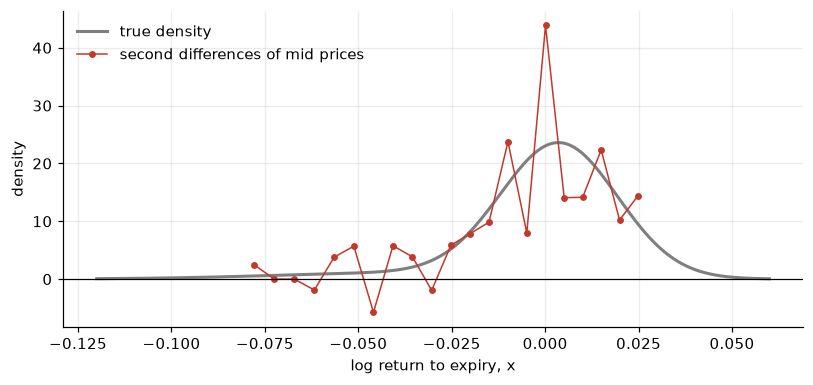

median half-spread 1.5e-04, so the error bound 4*eps/h^2 is about 24
peak of the true density of M: 24
3 of 21 naive density values are negative


In [6]:
mid5 = (BID5 + ASK5)/2
h = np.diff(M5)
g_naive = (mid5[2:] - mid5[1:-1])/h[1:]/((h[:-1] + h[1:])/2) - (mid5[1:-1] - mid5[:-2])/h[:-1]/((h[:-1] + h[1:])/2)
x_naive = np.log(M5[1:-1])
f_naive = M5[1:-1]*g_naive

xs = np.linspace(-0.12, 0.06, 600)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(xs, LAW["pdf"](xs), color=GRAY, lw=2, label="true density")
ax.plot(x_naive, f_naive, "o-", color=RED, ms=3.5, lw=1, label="second differences of mid prices")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("log return to expiry, x")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()
half5 = np.median((ASK5 - BID5)/2)
print(f"median half-spread {half5:.1e}, so the error bound 4*eps/h^2 is about {4*half5/0.005**2:.0f}")
print(f"peak of the true density of M: {(LAW['pdf'](xs)/np.exp(xs)).max():.0f}")
print(f"{(g_naive < 0).sum()} of {len(g_naive)} naive density values are negative")

The figure compares the true five-session density of the log return (gray) with the density from second differences of the noisy mid prices (red). The naive estimate swings around the truth, goes negative at some strikes and has no values at all beyond the last quoted strikes.

## 5. The closest arbitrage-free curve

Instead of differentiating the quotes, we look for the call curve that is as close as possible to the quotes among all curves that satisfy the three no-arbitrage conditions. Then we differentiate that curve. This idea goes back to Aït-Sahalia and Duarte (2003). The version here works directly with bid and ask quotes and reduces to a single non-negative least squares problem.

### 5.1 A parametrisation that makes the constraints automatic

Take the kept strikes $m_0 < m_1 < \dots < m_{n-1}$ as knots, and let $c$ be piecewise linear between them with slope $s_l$ on $[m_l, m_{l+1}]$. Convexity means the slopes never decrease, and the slope condition means they stay in $[-1, 0]$. Both are guaranteed if we write each slope as $-1$ plus a running sum of non-negative increments

$$
s_l = -1 + \sum_{j=0}^{l} a_j, \qquad a_j \ge 0
$$

The increment $a_j$ is the probability mass that the fitted distribution puts at knot $m_j$ ($a_0$ also holds any mass below $m_0$). Given the price at the last knot, $c_{n-1} \ge 0$, every other price follows by walking back along the slopes

$$
c_i = c_{n-1} - \sum_{l=i}^{n-2} s_l\, d_l, \qquad d_l = m_{l+1} - m_l
$$

Substituting the slopes and swapping the order of summation gives a linear map from the parameters to the prices. With $\tau_i = m_{n-1} - m_i$, the distance from knot $i$ to the last knot,

$$
c_i = c_{n-1} + \tau_i - \sum_{j=0}^{n-2} a_j\, \tau_{\max(i,j)}
$$

Two conditions are left. The last slope must be at most zero, which is $\sum_j a_j \le 1$, and the first price must be at least intrinsic, $c_0 \ge 1 - m_0$. Once these hold at the ends, the slopes carry them to every other point, because a curve with slopes at least $-1$ that starts above $1-m$ stays above it, and a decreasing curve that ends above zero stays above zero. We turn both into equalities with non-negative slack variables $u, v \ge 0$

$$
\sum_j a_j + u = 1, \qquad c_0 - v = 1 - m_0
$$

### 5.2 The fit is a non-negative least squares problem

Each quote gives a target, the mid, and a tolerance, the half-spread $\eta_i = (\text{ask}_i - \text{bid}_i)/2$, floored at half a tick so that a zero-width quote cannot get infinite weight. We minimise the squared misfit measured in half-spreads

$$
\min_{\theta \ge 0} \sum_i \left(\frac{c_i(\theta) - \text{mid}_i}{\eta_i}\right)^2, \qquad \theta = (c_{n-1}, a_0, \dots, a_{n-2}, u, v)
$$

subject to the two equalities. Every parameter is non-negative and the prices are linear in them, so this is a convex quadratic program. We solve it with the classic non-negative least squares algorithm of Lawson and Hanson (1974), and impose the two equalities as two extra rows with a large weight, $10^4$ times the largest quote weight. The equalities then hold to within about $10^{-7}$ in normalised units, far below one tick, and the checks below test exactly that.

A fitted price inside $[\text{bid}, \text{ask}]$ is as good as any other from the market's point of view. So the share of strikes where the fit lies inside the quotes, called `inside` below, is the natural quality score. A chain where the closest arbitrage-free curve cannot get inside most of the spreads has a data problem, and it is better to drop it than to trust it.

In [7]:
PENALTY = 1e4


def fit_calls(m, target, scale):
    """Arbitrage-free piecewise-linear call curve on knots m (ascending), closest to target in units of scale."""
    n = len(m)
    tau = np.append(np.cumsum(np.diff(m)[::-1])[::-1], 0.0)      # tau_i = m_{n-1} - m_i
    i, j = np.arange(n)[:, None], np.arange(n - 1)[None, :]
    B = np.column_stack([np.ones(n), -tau[np.maximum(i, j)], np.zeros((n, 2))])   # c = B theta + tau
    w = 1/scale
    big = PENALTY*w.max()
    A = np.vstack([B*w[:, None],
                   big*np.r_[0.0, np.ones(n - 1), 1.0, 0.0],                     # sum a + u = 1
                   big*(B[0] - np.r_[np.zeros(n + 1), 1.0])])                    # c_0 - v = 1 - m_0
    b = np.r_[(target - tau)*w, big, big*(1 - m[0] - tau[0])]
    theta = nnls(A, b, maxiter=50*n)[0]
    return B @ theta + tau


def fit_chain(q, d, tick=0.01):
    """Forward, kept quotes and fitted curve for one expiry, plus the share of strikes fitted inside the quotes."""
    F = forward(q, d)
    m, bid, ask = wings(q, F, d)
    c = fit_calls(m, (bid + ask)/2, np.maximum((ask - bid)/2, tick/2*d/F))
    inside = np.mean((c >= bid - 1e-12) & (c <= ask + 1e-12))
    return dict(F=F, m=m, bid=bid, ask=ask, c=c, inside=inside)


FIT5 = fit_chain(Q5, D5)
c5, m5 = FIT5["c"], FIT5["m"]
slope = np.diff(c5)/np.diff(m5)
print(f"inside the quotes at {FIT5['inside']:.0%} of {len(m5)} strikes")
check(slope.min() >= -1 - 1e-7 and slope.max() <= 1e-7, "every slope of the fit lies in [-1, 0]")
check(np.diff(slope).min() >= -1e-7, "the fit is convex (slopes never decrease)")
check(c5[-1] >= -1e-9 and (c5 - np.maximum(0, 1 - m5)).min() >= -1e-7, "the fit is never below intrinsic value or zero")
check(FIT5["inside"] == 1.0, "the closest arbitrage-free curve lies inside every bid-ask spread")

inside the quotes at 100% of 23 strikes
check passed: every slope of the fit lies in [-1, 0]
check passed: the fit is convex (slopes never decrease)
check passed: the fit is never below intrinsic value or zero
check passed: the closest arbitrage-free curve lies inside every bid-ask spread


A good fitting routine should also leave an arbitrage-free curve alone. If we feed it exact model prices it should return them almost unchanged.

In [8]:
m_exact = np.linspace(0.85, 1.08, 120)
c_exact = LAW["call"](m_exact)
c_back = fit_calls(m_exact, c_exact, np.full(len(m_exact), 1e-5))
err = np.abs(c_back - c_exact).max()
print(f"largest change to exact prices {err:.1e} (one cent on a 100 dollar underlying is 1e-4)")
check(err < 1e-6, "the fit returns arbitrage-free prices essentially unchanged")

largest change to exact prices 3.8e-13 (one cent on a 100 dollar underlying is 1e-4)
check passed: the fit returns arbitrage-free prices essentially unchanged


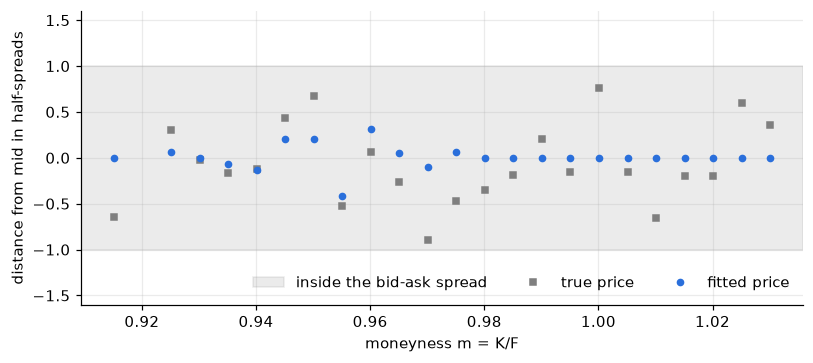

In [9]:
resid = (FIT5["c"] - (FIT5["bid"] + FIT5["ask"])/2)/((FIT5["ask"] - FIT5["bid"])/2)
K5 = FIT5["m"]*FIT5["F"]                               # true dollar prices, normalised like the quotes (by the estimated F)
c_true = LAW["call"](K5/F0)
c_true = np.where(K5 < FIT5["F"], c_true - 1 + K5/F0 + 1 - FIT5["m"], c_true)*F0/FIT5["F"]
true_resid = (c_true - (FIT5["bid"] + FIT5["ask"])/2)/((FIT5["ask"] - FIT5["bid"])/2)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.axhspan(-1, 1, color=GRAY, alpha=0.15, label="inside the bid-ask spread")
ax.plot(FIT5["m"], true_resid, "s", color=GRAY, ms=4, label="true price")
ax.plot(FIT5["m"], resid, "o", color=BLUE, ms=4, label="fitted price")
ax.set_xlabel("moneyness m = K/F")
ax.set_ylabel("distance from mid in half-spreads")
ax.set_ylim(-1.6, 1.6)
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

The figure shows, for each kept strike, how far the fitted price (blue) and the true model price (gray) sit from the quoted mid, measured in half-spreads. Everything inside the shaded band is inside the bid-ask spread. Both stay inside every spread. The fit sits closer to the mid than the truth does, because the quotes are all it sees. It moves away from the mid only where the mids themselves break the no-arbitrage conditions, here in the put wing. The fit cannot recover where the truth sits inside each spread, and it does not need to, since any price inside the spread is consistent with the market.

## 6. Quantiles from the fitted curve

On the interval $[m_l, m_{l+1}]$ the fitted curve has constant slope $s_l$, so the fitted CDF is the constant $1 + s_l$ there. The fitted distribution puts all its mass on the knots. That is why we do not report a density. A piecewise-linear call curve can only describe a discrete distribution, and a smooth density drawn from it would be decoration.

Quantiles are robust to this. We place each CDF value at the midpoint of its interval in log moneyness, interpolate linearly between midpoints, and use the generalised inverse

$$
q(p) = \inf\{x : \hat F(x) \ge p\}
$$

for $p = 2.5\%, 5\%, \dots, 97.5\%$. A quantile cannot be more precise than the strike grid, so the natural yardstick for its error is the strike spacing, here 0.50 dollars or 0.23 standard deviations of the five-session return. A quantile is reported only when the fitted CDF actually passes through $p$ inside the quoted range. Outside the strikes the curve says nothing, and the code returns a missing value instead of guessing.

In [10]:
P = np.round(np.arange(0.025, 0.97501, 0.025), 3)        # 39 probability levels


def quantiles(m, c, p=P):
    """Quantiles of x = ln m from a piecewise-linear call curve, NaN where the curve does not cover p."""
    x = np.log(m)
    cdf = np.clip(1 + np.diff(c)/np.diff(m), 0.0, 1.0)
    xm = (x[1:] + x[:-1])/2
    j = np.searchsorted(cdf, p, side="left")               # first midpoint with CDF >= p
    q = np.full(len(p), np.nan)
    ok = (j > 0) & (j < len(cdf))
    jj = j[ok]
    q[ok] = xm[jj - 1] + (p[ok] - cdf[jj - 1])/(cdf[jj] - cdf[jj - 1])*(xm[jj] - xm[jj - 1])
    return q


xgrid = np.linspace(-1.0, 0.5, 400001)
TRUE_Q = np.interp(P, LAW["cdf"](xgrid), xgrid)
q5 = quantiles(FIT5["m"], FIT5["c"])
qerr = np.nanmax(np.abs(q5 - TRUE_Q))/LAW["sd"]
GAP_SD = 0.5/F0/LAW["sd"]                                # one strike spacing in sd of the five-session return
print(f"{np.isfinite(q5).sum()} of {len(P)} quantiles covered, median error {np.nanmedian(np.abs(q5 - TRUE_Q))/LAW['sd']:.3f}, "
      f"largest {qerr:.3f} standard deviations (one strike spacing is {GAP_SD:.3f})")
check(qerr < GAP_SD, "every fitted quantile is within one strike spacing of the true one")

37 of 39 quantiles covered, median error 0.042, largest 0.203 standard deviations (one strike spacing is 0.225)
check passed: every fitted quantile is within one strike spacing of the true one


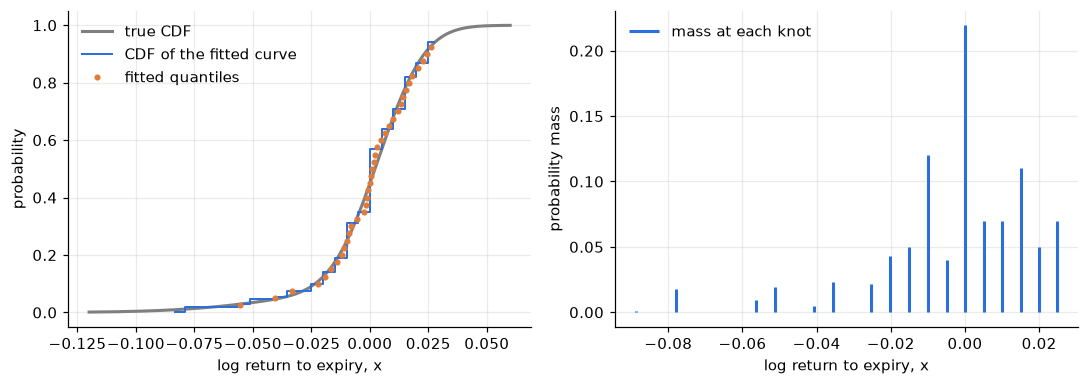

In [11]:
x_mid = np.log(FIT5["m"][1:]*FIT5["m"][:-1])/2
cdf_fit = 1 + np.diff(FIT5["c"])/np.diff(FIT5["m"])
mass = np.diff(np.r_[0.0, cdf_fit])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.plot(xs, LAW["cdf"](xs), color=GRAY, lw=2, label="true CDF")
ax.step(x_mid, cdf_fit, where="mid", color=BLUE, lw=1.3, label="CDF of the fitted curve")
ax.plot(q5, P, "o", color=ORANGE, ms=3, label="fitted quantiles")
ax.set_xlabel("log return to expiry, x")
ax.set_ylabel("probability")
ax.legend(loc="upper left")
ax = axes[1]
ax.vlines(np.log(FIT5["m"][:-1]), 0, mass, color=BLUE, lw=2, label="mass at each knot")
ax.set_xlabel("log return to expiry, x")
ax.set_ylabel("probability mass")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The left panel compares the true CDF (gray) with the CDF of the fitted curve (blue steps) and the 39 fitted quantiles (orange). The right panel shows where the fitted distribution puts its probability mass. The mass sits on the knots and is lumpy, because a piecewise-linear call curve can only describe a discrete distribution, yet the CDF and the quantiles follow the truth closely.

## 7. A constant horizon of five sessions

Listed expiries do not sit at the horizon we care about. On a given day the nearest weekly options might expire in 3 and 8 sessions, while we want the distribution of the return over exactly five sessions. Comparing distributions across days only makes sense at a fixed horizon, otherwise the numbers move just because expiries roll.

### 7.1 Total implied variance

Each fitted curve is turned into implied volatilities by inverting the normalised Black formula at every strike. With total standard deviation $\sigma_{\text{imp}}\sqrt t$ to expiry, the normalised Black call price is

$$
c_{\text{BS}}(m, \sqrt w) = \Phi(d_1) - m\,\Phi(d_1 - \sqrt w), \qquad d_1 = \frac{-\ln m}{\sqrt w} + \frac{\sqrt w}{2}
$$

where $w = \sigma_{\text{imp}}^2 t$ is the total implied variance. The price is increasing in $w$, so bisection on the out-of-the-money price finds $w$ at each strike.

### 7.2 Interpolating along standardised moneyness

We interpolate total variance in time, at fixed standardised moneyness $y = x/\sqrt t$. For expiries $t_{lo} < H \le t_{hi}$ the target smile is

$$
w_H(x) = w_{lo}\left(y\sqrt{t_{lo}}\right) + \frac{H - t_{lo}}{t_{hi} - t_{lo}}\left[w_{hi}\left(y\sqrt{t_{hi}}\right) - w_{lo}\left(y\sqrt{t_{lo}}\right)\right], \qquad y = \frac{x}{\sqrt H}
$$

Two reasons for this choice. First, total variance grows roughly linearly with time, so linear interpolation in $t$ is the natural first guess. Second, a strike that is one standard deviation out of the money at 3 sessions is closer in risk to a strike one standard deviation out at 8 sessions than to the same $x$. Lining up smiles by $y$ compares like with like.

A flat smile is reproduced exactly. If $w_t(x) = \sigma^2 t$ at every $x$, the formula gives $\sigma^2 t_{lo} + (H - t_{lo})\sigma^2 = \sigma^2 H$. With only one usable expiry at $t \ge H$ we scale it, $w_H(x) = \tfrac{H}{t}\, w_t(x\sqrt{t/H})$.

For a non-flat smile the method is an assumption, not an identity. Two expiries do not determine the distribution in between, and any interpolation picks one answer. The check below measures how far it lands from the true Merton law.

### 7.3 Back to prices, and back to the arbitrage-free set

The target smile is converted back to call prices on a grid of 400 points over the common range of $y$, and the prices are checked against the three conditions of Section 2.3. Interpolating two arbitrage-free smiles does not guarantee an arbitrage-free result, so if the check fails the grid is projected onto the arbitrage-free set with the same `fit_calls`, using equal weights.

In [12]:
def black(m, s, call):
    """Normalised undiscounted Black price (F = 1) at moneyness m and total standard deviation s."""
    d1 = -np.log(m)/s + s/2
    return np.where(call, norm.cdf(d1) - m*norm.cdf(d1 - s), m*norm.cdf(s - d1) - norm.cdf(-d1))


def total_variance(m, c):
    """Total implied variance by bisection on the out-of-the-money price, NaN where it cannot be inverted."""
    call = m >= 1
    o = np.where(call, c, c - (1 - m))
    lo, hi = np.full(len(m), 1e-5), np.full(len(m), 2.0)
    ok = (o > 1e-7) & (black(m, lo, call) < o) & (o < black(m, hi, call))
    for _ in range(60):
        s = (lo + hi)/2
        up = black(m, s, call) < o
        lo, hi = np.where(up, s, lo), np.where(up, hi, s)
    return np.where(ok, ((lo + hi)/2)**2, np.nan)


def target_curve(curves, ts, t=H, grid=400):
    """Normalised call curve at t sessions from one or two (m, w) smiles at ts sessions (Section 7.2)."""
    if len(curves) == 1:
        (m1, w1), (t1,) = curves, ts
        lo, hi = np.log(m1[0])/np.sqrt(t1), np.log(m1[-1])/np.sqrt(t1)
    else:
        (m1, w1), (m2, w2) = curves
        t1, t2 = ts
        lo = max(np.log(m1[0])/np.sqrt(t1), np.log(m2[0])/np.sqrt(t2))
        hi = min(np.log(m1[-1])/np.sqrt(t1), np.log(m2[-1])/np.sqrt(t2))
    y = np.linspace(lo, hi, grid)
    at = lambda mm, ww, tt: np.interp(y*np.sqrt(tt), np.log(mm), ww)
    if len(curves) == 1:
        wt = t/t1*at(m1, w1, t1)
    else:
        wt = at(m1, w1, t1) + (t - t1)/(t2 - t1)*(at(m2, w2, t2) - at(m1, w1, t1))
    m = np.exp(y*np.sqrt(t))
    c = black(m, np.sqrt(wt), True)
    s = np.diff(c)/np.diff(m)
    if (s >= -1 - 1e-10).all() and (s <= 1e-10).all() and (np.diff(s) >= -1e-10).all():
        return m, c                                 # already arbitrage-free
    return m, fit_calls(m, c, np.full(grid, 1e-4))


def smile(fit):
    w = total_variance(fit["m"], fit["c"])
    ok = np.isfinite(w)
    return fit["m"][ok], w[ok]

First the exact case. Two lognormal laws at 3 and 8 sessions with the same volatility per session have a flat smile, so the interpolated five-session law must be lognormal with variance $5\sigma^2$. We use exact prices here, so that only the interpolation is tested.

In [13]:
flat = []
for t in (3, 8):
    mm = np.exp(np.linspace(-0.15, 0.10, 300))
    flat.append(smile(dict(m=mm, c=merton(t, lam=0.0)["call"](mm))))
m_f, c_f = target_curve(flat, (3, 8))
sd_flat = SIG*np.sqrt(H)
q_flat = quantiles(m_f, c_f)
q_true_flat = -sd_flat**2/2 + sd_flat*norm.ppf(P)
err_flat = np.nanmax(np.abs(q_flat - q_true_flat))/sd_flat
print(f"flat smile: largest quantile error {err_flat:.3f} standard deviations")
check(err_flat < 0.01, "a flat smile at 3 and 8 sessions interpolates to the right lognormal at 5 sessions")

flat smile: largest quantile error 0.000 standard deviations
check passed: a flat smile at 3 and 8 sessions interpolates to the right lognormal at 5 sessions


Now the Merton market, where the smile is not flat. We run it twice. With exact prices on a fine grid the only error is the interpolation assumption itself. With chains quoted with noise as before, the error also includes the quotes and the strike spacing. The noisy case is repeated on 20 random chains, so that the result does not hang on one lucky or unlucky draw.

In [14]:
exact = []
for t in (3, 8):
    mm = np.exp(np.linspace(-0.5, 0.25, 600))
    exact.append(smile(dict(m=mm, c=merton(t)["call"](mm))))
err_e = np.abs(quantiles(*target_curve(exact, (3, 8))) - TRUE_Q)/LAW["sd"]

med_err, max_err = [], []
for seed in range(20):
    fits = {t: fit_chain(quotes(merton(t), rng=np.random.default_rng(100*seed + t)), disc(t)) for t in (3, 8)}
    e = np.abs(quantiles(*target_curve([smile(fits[t]) for t in (3, 8)], (3, 8))) - TRUE_Q)/LAW["sd"]
    med_err.append(np.nanmedian(e))
    max_err.append(np.nanmax(e))
    if seed == 0:
        FITS = fits                                  # kept for the figure below

print(f"exact prices: quantile error in sd, median {np.median(err_e):.3f}, max {err_e.max():.3f} (at p = {P[np.argmax(err_e)]:.3f})")
print(f"noisy quotes, 20 chains: median error {np.median(med_err):.3f} sd, largest error per chain "
      f"median {np.median(max_err):.3f} and worst {np.max(max_err):.3f} (one strike spacing is {GAP_SD:.3f} sd)")
check(err_e.max() < 0.1, "the interpolation assumption alone moves no quantile by more than 0.1 sd")
check(np.median(max_err) < GAP_SD, "with noisy quotes the typical largest quantile error is below one strike spacing")

exact prices: quantile error in sd, median 0.007, max 0.081 (at p = 0.025)
noisy quotes, 20 chains: median error 0.039 sd, largest error per chain median 0.200 and worst 0.434 (one strike spacing is 0.225 sd)
check passed: the interpolation assumption alone moves no quantile by more than 0.1 sd
check passed: with noisy quotes the typical largest quantile error is below one strike spacing


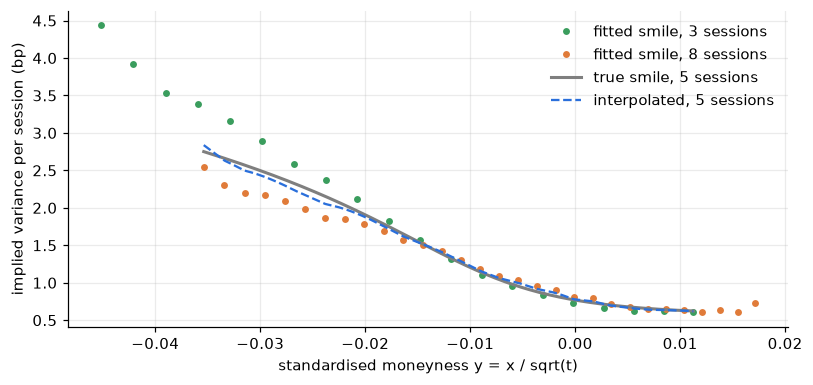

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
SMILES = [smile(FITS[t]) for t in (3, 8)]
M_T, C_T = target_curve(SMILES, (3, 8))
for (mm, ww), t, col in zip(SMILES, (3, 8), (GREEN, ORANGE)):
    ax.plot(np.log(mm)/np.sqrt(t), ww/t*1e4, "o", ms=3.5, color=col, label=f"fitted smile, {t} sessions")
m_true = np.exp(np.linspace(np.log(M_T[0]), np.log(M_T[-1]), 300))
ax.plot(np.log(m_true)/np.sqrt(H), total_variance(m_true, LAW["call"](m_true))/H*1e4, color=GRAY, lw=2, label="true smile, 5 sessions")
ax.plot(np.log(M_T)/np.sqrt(H), total_variance(M_T, C_T)/H*1e4, color=BLUE, lw=1.5, ls="--", label="interpolated, 5 sessions")
ax.set_xlabel("standardised moneyness y = x / sqrt(t)")
ax.set_ylabel("implied variance per session (bp)")
ax.legend()
plt.tight_layout()
plt.show()

The figure plots implied variance per session against standardised moneyness for the two fitted expiries (green and orange), the interpolated five-session smile (blue dashed) and the true five-session smile (gray). The interpolated smile lies between the two expiries and close to the truth over the covered range. The curves end where the strikes end, so nothing is said about the far tails.

## 8. Moments from option prices

### 8.1 The spanning formula

Any smooth payoff can be built from a bond, a forward and a strip of out-of-the-money options. For a twice differentiable function $g$, Taylor's theorem with the remainder in integral form, expanded around $1$, says

$$
g(M) = g(1) + g'(1)(M-1) + \int_0^1 g''(k)\,(k-M)^+\,dk + \int_1^\infty g''(k)\,(M-k)^+\,dk
$$

Take risk-neutral expectations. The forward term drops out because $\mathbb{E}[M] = 1$, and the two integrals become put and call prices

$$
\mathbb{E}^{\mathbb{Q}}[g(M)] = g(1) + \int_0^\infty g''(k)\,o(k)\,dk, \qquad o(k) = \begin{cases} p(k) & k < 1 \\ c(k) & k \ge 1 \end{cases}
$$

This is the spanning result of Carr and Madan (1998) and Bakshi, Kapadia and Madan (2003), here written in normalised units so that no discount factors appear.

### 8.2 The four power contracts

For the raw moments of $x = \ln M$ we need $g(m) = (\ln m)^n$, which has $g(1) = 0$. The second derivatives are

$$
g_1'' = -\frac{1}{m^2}, \qquad g_2'' = \frac{2(1-\ln m)}{m^2}, \qquad g_3'' = \frac{6\ln m - 3(\ln m)^2}{m^2}, \qquad g_4'' = \frac{12(\ln m)^2 - 4(\ln m)^3}{m^2}
$$

Integrating each against $o(m)$ gives $\mathbb{E}[x^n]$ for $n = 1, \dots, 4$, and the central moments follow from the usual expansions

$$
\mu = \mathbb{E}[x], \qquad \text{var} = \mathbb{E}[x^2] - \mu^2
$$

$$
\text{skew} = \frac{\mathbb{E}[x^3] - 3\mu\,\mathbb{E}[x^2] + 2\mu^3}{\text{var}^{3/2}}, \qquad \text{kurt} = \frac{\mathbb{E}[x^4] - 4\mu\,\mathbb{E}[x^3] + 6\mu^2\,\mathbb{E}[x^2] - 3\mu^4}{\text{var}^2}
$$

The integrals are computed with the trapezoidal rule on the fitted curve, after inserting the point $m = 1$ where $o$ switches from puts to calls.

In [16]:
def bkm(m, c):
    """Mean, variance, skewness and kurtosis of x from the spanning integrals over the covered range of m."""
    k = np.searchsorted(m, 1.0)
    mm, cc = np.insert(m, k, 1.0), np.insert(c, k, np.interp(1.0, m, c))
    o = np.where(mm >= 1, cc, cc - (1 - mm))
    xx = np.log(mm)
    span = lambda g2: np.trapezoid(g2*o, mm)
    e1 = span(-1/mm**2)
    e2 = span(2*(1 - xx)/mm**2)
    e3 = span((6*xx - 3*xx**2)/mm**2)
    e4 = span((12*xx**2 - 4*xx**3)/mm**2)
    var = e2 - e1**2
    skew = (e3 - 3*e1*e2 + 2*e1**3)/var**1.5
    kurt = (e4 - 4*e1*e3 + 6*e1**2*e2 - 3*e1**4)/var**2
    return dict(mean=e1, var=var, skew=skew, kurt=kurt)


m_wide = np.exp(np.linspace(-20*LAW["sd"], 8*LAW["sd"], 4001))
full = bkm(m_wide, LAW["call"](m_wide))
print(f"exact prices from -20 to +8 sd: skew {full['skew']:.4f} (true {LAW['skew']:.4f}), kurt {full['kurt']:.4f} (true {LAW['kurt']:.4f})")
check(abs(full["skew"] - LAW["skew"]) < 1e-3 and abs(full["kurt"] - LAW["kurt"]) < 1e-2,
      "with a wide enough strike range the spanning integrals recover the true skewness and kurtosis")

exact prices from -20 to +8 sd: skew -1.5618 (true -1.5618), kurt 8.5626 (true 8.5627)
check passed: with a wide enough strike range the spanning integrals recover the true skewness and kurtosis


### 8.3 A pitfall with the mean

Bakshi, Kapadia and Madan write their contracts for the return relative to today's spot, $\ln(S_T/S_0)$, with discounted option prices. Their mean is a Taylor approximation

$$
\mu_{\text{BKM}} = e^{rT} - 1 - \frac{e^{rT}}{2}V - \frac{e^{rT}}{6}W - \frac{e^{rT}}{24}X
$$

where $V$, $W$ and $X$ are the prices of the second, third and fourth power contracts. Around the forward, the term $e^{rT} - 1$ must go, because $\mathbb{E}[e^x] = 1$ exactly. Using the spot formula with forward-based contracts adds a spurious drift of about $rT$ to the mean. It sounds tiny, but it enters the skewness through $\mu$, and with a short horizon the variance is tiny too. The exact mean from the log contract, $\mathbb{E}[x] = -\int o(m)/m^2\,dm$, avoids both the Taylor error and the rate term.

The cell below shows the size of the error for a lognormal law with 20% annual volatility and seven days to expiry. The true skewness is zero.

In [17]:
T7 = 7/365
s7 = 0.2*np.sqrt(T7)
m_ln = np.arange(50, 150.001, 0.01)/100
o_ln = np.where(m_ln >= 1, black(m_ln, s7, True), black(m_ln, s7, False))
xl = np.log(m_ln)
V, W, X = (np.trapezoid(g*o_ln, m_ln) for g in (2*(1 - xl)/m_ln**2, (6*xl - 3*xl**2)/m_ln**2, (12*xl**2 - 4*xl**3)/m_ln**2))


def skew_from(mu):
    return (W - 3*mu*V + 2*mu**3)/(V - mu**2)**1.5


rows = []
for r in (0.0, 0.05):
    rows.append((r, skew_from(np.exp(r*T7) - 1 - V/2 - W/6 - X/24), skew_from(-V/2 - W/6 - X/24), skew_from(bkm(m_ln, black(m_ln, s7, True))["mean"])))
print(" rate   spot-style mean   Taylor around F   exact log contract")
for r, a, b, c in rows:
    print(f"{r:5.0%} {a:17.4f} {b:17.4f} {c:20.4f}")
check(rows[1][1] < -0.1 and abs(rows[1][3]) < 1e-4, "the spot-style mean fakes a skew of about -0.10 at a 5% rate and the log-contract mean gives zero")

 rate   spot-style mean   Taylor around F   exact log contract
   0%            0.0000            0.0000               0.0000
   5%           -0.1039            0.0000               0.0000
check passed: the spot-style mean fakes a skew of about -0.10 at a 5% rate and the log-contract mean gives zero


## 9. What a truncated moment really measures

The spanning integrals run over all strikes from zero to infinity. Real chains stop where the bids vanish, so in practice the integrals are cut off at the last quoted strike on each side. Section 8 checked that the formulas are right when the range is wide. This section asks what happens at the ranges real chains actually have.

### 9.1 Where the fourth moment lives

The fourth central moment weights each outcome by $(x-\mu)^4$. An outcome four standard deviations out counts 256 times as much as one at one standard deviation. For a fat-tailed law a large part of the kurtosis therefore comes from outcomes that are so rare that the options covering them are barely quoted.

The figure below measures this directly from the true Merton density. For each $k$ it shows the share of the fourth central moment that comes from outcomes more than $k$ standard deviations below the mean. A normal law with the same variance is shown for comparison.

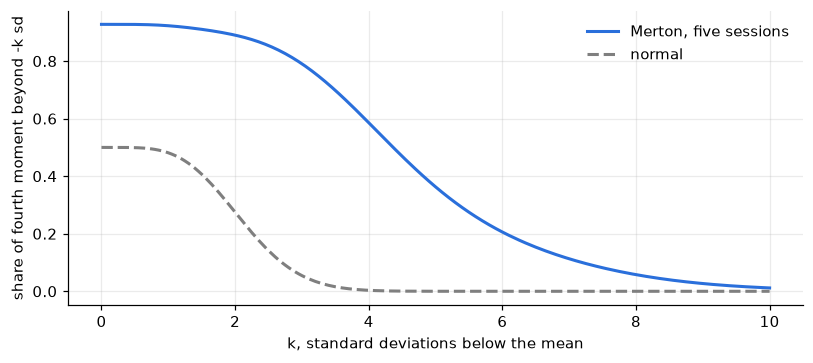

beyond -3 sd: Merton 79% of the fourth moment, normal 5.5%
beyond -4 sd: Merton 59% of the fourth moment, normal 0.3%
beyond -6 sd: Merton 21% of the fourth moment, normal 0.0%


In [18]:
z = (xg - LAW["mean"])/LAW["sd"]
contrib = z**4*fx
ks = np.linspace(0, 10, 201)
share_m = np.array([np.trapezoid(np.where(z < -k, contrib, 0), xg) for k in ks])/np.trapezoid(contrib, xg)
share_n = np.array([np.trapezoid(np.where(z < -k, z**4*norm.pdf(z), 0), z) for k in ks])/3     # N(0,1) has E[z^4] = 3

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(ks, share_m, color=BLUE, lw=2, label="Merton, five sessions")
ax.plot(ks, share_n, color=GRAY, lw=2, ls="--", label="normal")
ax.set_xlabel("k, standard deviations below the mean")
ax.set_ylabel("share of fourth moment beyond -k sd")
ax.legend()
plt.tight_layout()
plt.show()
for k in (3, 4, 6):
    print(f"beyond -{k} sd: Merton {np.interp(k, ks, share_m):.0%} of the fourth moment, normal {np.interp(k, ks, share_n):.1%}")

The figure plots the share of the fourth central moment that comes from outcomes more than $k$ standard deviations below the mean, for the five-session Merton law (blue) and a normal law (gray dashed). For the normal law almost nothing lies beyond 4 standard deviations. For the Merton law a large share of the kurtosis comes from beyond 4 standard deviations, which is exactly where option quotes run out.

### 9.2 Cutting the strike range

Now we compute BKM skewness and kurtosis from exact Merton prices, with no noise at all, but only on strikes from $-L$ standard deviations up to $+2.5$. As a contrast we compute a quantile-based tail measure from the same curves, the ratio of the lower to the upper spread

$$
\text{tail ratio} = \frac{q(50\%) - q(10\%)}{q(90\%) - q(50\%)}
$$

It is above 1 when the left tail is longer than the right tail. It only needs the curve to cover the 10% and 90% quantiles, which every chain here does.

For each truncated curve we also report the reach the way it would be reported from data, as $\ln(m_{\min})$ divided by the standard deviation of the same truncated curve. This is the number called `lo_sd` in the real-data section.

In [19]:
def tail_ratio(q):
    return (q[19] - q[3])/(q[35] - q[19])          # P[3] = 10%, P[19] = 50%, P[35] = 90%


TRUE_TR = tail_ratio(TRUE_Q)
trunc = []
for L in np.arange(2.0, 14.01, 0.5):
    mm = np.exp(np.linspace(-L*LAW["sd"], 2.5*LAW["sd"], 2001))
    cc = LAW["call"](mm)
    b = bkm(mm, cc)
    trunc.append((L, np.log(mm[0])/np.sqrt(b["var"]), b["skew"], b["kurt"], tail_ratio(quantiles(mm, cc))))
trunc = np.array(trunc)
print("  L   lo_sd    skew    kurt   tail ratio")
for row in trunc[[0, 2, 4, 6, 8, 12, 16, 24]]:
    print(f"{row[0]:4.1f} {row[1]:7.2f} {row[2]:7.3f} {row[3]:7.3f} {row[4]:10.4f}")
check(np.all(np.diff(trunc[:, 3]) > 0), "BKM kurtosis rises with every extra half standard deviation of strike reach")
check(np.ptp(trunc[:, 4]) < 1e-3 and abs(trunc[0, 4] - TRUE_TR) < 1e-3, "the quantile tail ratio is the same at every reach and equals the true one")

  L   lo_sd    skew    kurt   tail ratio
 2.0   -2.11  -0.820   3.792     1.2177
 3.0   -3.06  -1.225   5.707     1.2177
 4.0   -4.02  -1.424   7.095     1.2177
 5.0   -5.01  -1.508   7.867     1.2177
 6.0   -6.00  -1.542   8.247     1.2177
 8.0   -8.00  -1.561   8.506     1.2177
10.0  -10.00  -1.563   8.551     1.2177
14.0  -14.00  -1.563   8.557     1.2177
check passed: BKM kurtosis rises with every extra half standard deviation of strike reach
check passed: the quantile tail ratio is the same at every reach and equals the true one


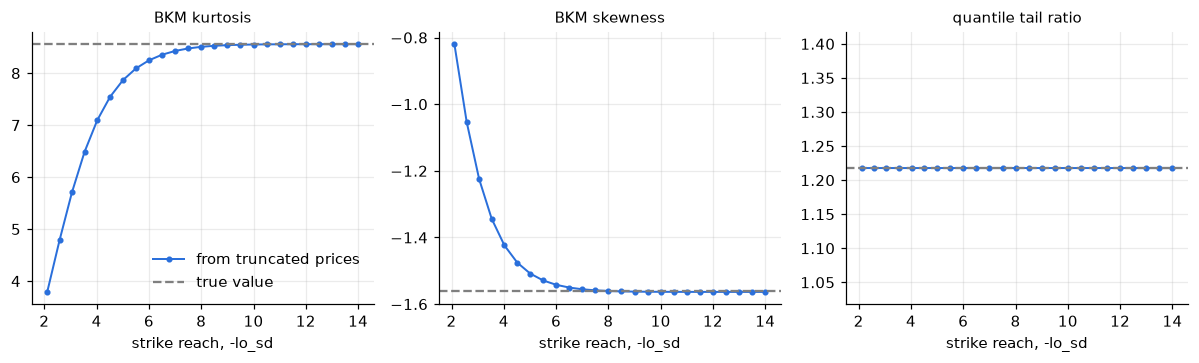

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, true, name in zip(axes, (3, 2, 4), (LAW["kurt"], LAW["skew"], TRUE_TR), ("BKM kurtosis", "BKM skewness", "quantile tail ratio")):
    ax.plot(-trunc[:, 1], trunc[:, col], "o-", color=BLUE, ms=3, lw=1.3, label="from truncated prices")
    ax.axhline(true, color=GRAY, ls="--", lw=1.5, label="true value")
    ax.set_xlabel("strike reach, -lo_sd")
    ax.set_title(name, fontsize=10)
axes[0].legend(loc="lower right")
axes[2].set_ylim(TRUE_TR - 0.2, TRUE_TR + 0.2)
plt.tight_layout()
plt.show()

The three panels use the same exact Merton prices cut off at a lower strike between 2 and 14 standard deviations below the forward. BKM kurtosis (left) climbs from below 4 to its true value of 8.6 only once the strikes reach about 10 standard deviations, and BKM skewness (middle) needs about 7. The quantile tail ratio (right) is exactly right at every reach.

### 9.3 The same effect through the quoting grid

In real chains nobody chooses $L$. The reach is set by the wing rule, which stops where the bids vanish, and that depends on the tick size relative to the price of the underlying, on spreads and on how many strikes the exchange lists. The cell below runs the full pipeline of Sections 3 to 6 on the five-session Merton chain with different tick sizes, 20 random quote draws each. Nothing about the true distribution changes between rows.

In [21]:
tick_rows = []
for tick in (0.05, 0.02, 0.01, 0.005, 0.002, 0.001, 0.0005):
    res = []
    for seed in range(20):
        fit = fit_chain(quotes(LAW, tick=tick, rng=np.random.default_rng(seed)), D5, tick=tick)
        b = bkm(fit["m"], fit["c"])
        q = quantiles(fit["m"], fit["c"])
        res.append((np.log(fit["m"][0])/np.sqrt(b["var"]), b["skew"], b["kurt"], tail_ratio(q),
                    fit["inside"], np.nanmax(np.abs(q - TRUE_Q))/LAW["sd"]))
    res = np.array(res)
    tick_rows.append((tick, *np.nanmean(res, axis=0), np.isfinite(res[:, 3]).mean()))
tick_rows = np.array(tick_rows)
print("  tick   lo_sd    skew    kurt  tail ratio  covered  inside  max quantile error (sd)")
for r in tick_rows:
    print(f"{r[0]:6.4f} {r[1]:7.2f} {r[2]:7.3f} {r[3]:7.3f} {r[4]:11.3f} {r[7]:8.0%} {r[5]:7.0%} {r[6]:10.2f}")
print(f"true             {LAW['skew']:7.3f} {LAW['kurt']:7.3f} {TRUE_TR:11.3f}")
check(np.all(np.diff(tick_rows[:, 1]) < 0) and np.all(np.diff(tick_rows[:, 3]) > 0),
      "a finer tick reaches deeper and raises BKM kurtosis, with the same true distribution")
full_cover = tick_rows[:, 7] == 1
check(np.abs(tick_rows[full_cover, 4] - TRUE_TR).max() < 0.02, "from a 1 cent tick on the tail ratio is always available and within 0.02 of the truth")

  tick   lo_sd    skew    kurt  tail ratio  covered  inside  max quantile error (sd)
0.0500   -2.36  -1.137   4.263       1.676      10%    100%       0.65
0.0200   -3.21  -1.342   5.899       1.309      55%    100%       0.33
0.0100   -3.80  -1.434   6.754       1.219     100%    100%       0.22
0.0050   -4.25  -1.462   7.198       1.219     100%    100%       0.18
0.0020   -5.12  -1.511   7.800       1.224     100%    100%       0.15
0.0010   -5.74  -1.527   8.046       1.220     100%    100%       0.14
0.0005   -6.27  -1.535   8.182       1.225     100%    100%       0.12
true              -1.562   8.563       1.218
check passed: a finer tick reaches deeper and raises BKM kurtosis, with the same true distribution
check passed: from a 1 cent tick on the tail ratio is always available and within 0.02 of the truth


With a tick of 5 cents the strikes reach only about 2.3 standard deviations and BKM kurtosis reads about 4. With a tick of 0.05 cents they reach about 6 and kurtosis reads about 8. The true law is the same in every row, so the change in kurtosis is entirely a change in how far the quotes reach. From a 1 cent tick on, the tail ratio is always available and within 0.02 of the truth, while kurtosis still moves from 6.8 to 8.2. With 5 and 2 cent ticks the call quotes often stop before the 90% quantile (the `covered` column). The ratio is then missing, and on the draws where the 90% quantile sits right at the edge of the curve it is biased. A quantile measure is only safe when its probability window lies well inside the quoted range, which is the same rule as for moments, but a much easier one to meet.

The practical rule is to report the covered range, `lo_sd` and `hi_sd`, next to every option-implied moment, and to ask whether a change in a moment is more than a change in reach. For anything that is meant to be compared over time or across underlyings, quantiles inside a fixed probability window are the safer measure.

## 10. Real chains, SPY, QQQ and IWM, 2011 to 2025

The functions above were applied to end-of-day option chains for SPY, QQQ and IWM from January 2011 to December 2025, about 3,700 trading days per ETF. The real pipeline adds three rules to what is shown here. It uses every expiry within 45 days, keeps an expiry only if the fit is inside at least 90% of the spreads and at most 10% of quotes near the money are invalid, and interpolates to five sessions from the nearest usable expiries on either side.

The option data are licensed for private use and are not part of this repository. The cells below contain only aggregate numbers taken from that run, and every figure is drawn from them.

The fit quality is high. The average `inside` share is 99.5% to 99.9% and moments are available on more than 99% of days. The median day has the lower strikes reaching 8.3 standard deviations for SPY but only 5.1 for QQQ and 4.7 for IWM.

In [22]:
# Medians over all days with moments and quantiles, and Spearman correlations with strike reach (-lo_sd),
# over all days and as the median of the 15 within-year correlations.
REAL = {
    #        days  reach   kurt   skew  tail  corr(kurt) corr(skew) corr(tail) | within-year: kurt  skew   tail
    "SPY": (3731, 8.30, 17.12, -2.15, 1.58, 0.89, -0.76, -0.16, 0.92, -0.82, -0.13),
    "QQQ": (3668, 5.11,  7.95, -1.37, 1.48, 0.87, -0.63, -0.07, 0.95, -0.82, -0.09),
    "IWM": (3723, 4.72,  6.82, -1.14, 1.43, 0.85, -0.47, -0.24, 0.93, -0.79,  0.01),
}
print("        days  reach   kurt   skew  tail ratio | Spearman with reach: kurt  skew  tail | within-year: kurt  skew  tail")
for k, v in REAL.items():
    print(f"{k}  {v[0]:6d} {v[1]:6.2f} {v[2]:6.2f} {v[3]:6.2f} {v[4]:11.2f} |{v[5]:26.2f} {v[6]:5.2f} {v[7]:5.2f} |{v[8]:18.2f} {v[9]:5.2f} {v[10]:5.2f}")

        days  reach   kurt   skew  tail ratio | Spearman with reach: kurt  skew  tail | within-year: kurt  skew  tail
SPY    3731   8.30  17.12  -2.15        1.58 |                      0.89 -0.76 -0.16 |              0.92 -0.82 -0.13
QQQ    3668   5.11   7.95  -1.37        1.48 |                      0.87 -0.63 -0.07 |              0.95 -0.82 -0.09
IWM    3723   4.72   6.82  -1.14        1.43 |                      0.85 -0.47 -0.24 |              0.93 -0.79  0.01


Across days, BKM kurtosis has a rank correlation of 0.85 to 0.89 with strike reach, and within a calendar year it is 0.92 to 0.95. Skewness is almost as tied to reach. The quantile tail ratio is close to unrelated to reach, between $-0.24$ and $0.01$. The yearly medians below show the same thing over time.

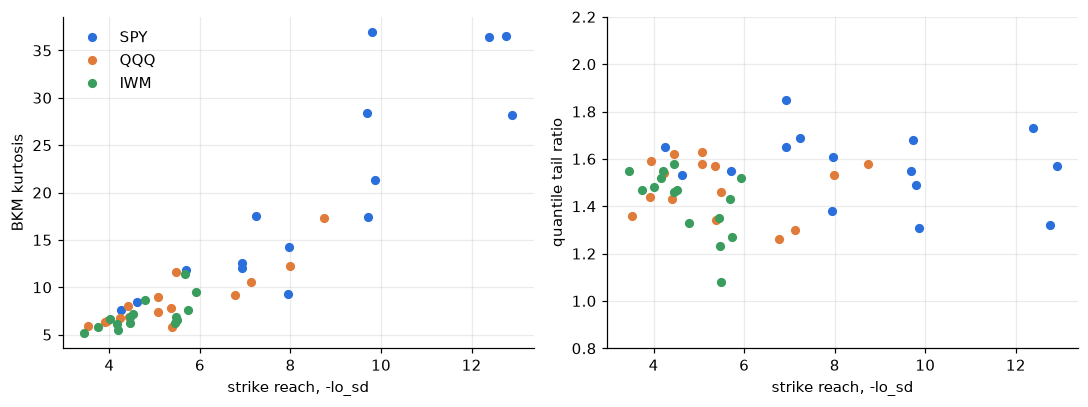

across the 45 ETF-years: rank correlation with reach, kurtosis 0.89, tail ratio 0.05
check passed: on real chains yearly kurtosis follows strike reach and the tail ratio does not


In [23]:
YEARS = np.arange(2011, 2026)
YEARLY = {   # yearly medians: strike reach (-lo_sd), BKM kurtosis, quantile tail ratio
    "SPY": ([4.25, 4.62, 5.70, 7.24, 6.92, 6.92, 9.80, 9.69, 7.96, 9.72, 12.38, 7.95, 9.87, 12.75, 12.90],
            [7.63, 8.47, 11.78, 17.49, 12.07, 12.56, 36.96, 28.38, 14.26, 17.46, 36.41, 9.31, 21.30, 36.51, 28.19],
            [1.65, 1.53, 1.55, 1.69, 1.85, 1.65, 1.49, 1.55, 1.61, 1.68, 1.73, 1.38, 1.31, 1.32, 1.57]),
    "QQQ": ([3.94, 3.91, 3.52, 4.41, 4.44, 4.24, 5.48, 5.07, 5.07, 5.35, 8.73, 5.38, 6.77, 7.13, 7.99],
            [6.49, 6.32, 5.88, 7.98, 6.91, 6.79, 11.60, 8.99, 7.34, 7.83, 17.34, 5.86, 9.22, 10.61, 12.28],
            [1.59, 1.44, 1.36, 1.43, 1.62, 1.54, 1.46, 1.63, 1.58, 1.57, 1.58, 1.34, 1.26, 1.30, 1.53]),
    "IWM": ([3.45, 3.74, 4.01, 4.52, 4.46, 4.17, 4.78, 5.68, 4.46, 4.20, 5.92, 5.44, 5.47, 5.49, 5.74],
            [5.15, 5.83, 6.66, 7.18, 6.82, 6.10, 8.64, 11.45, 6.24, 5.46, 9.48, 6.20, 6.88, 6.59, 7.57],
            [1.55, 1.47, 1.48, 1.47, 1.58, 1.52, 1.33, 1.43, 1.46, 1.55, 1.52, 1.35, 1.23, 1.08, 1.27]),
}
COLORS = {"SPY": BLUE, "QQQ": ORANGE, "IWM": GREEN}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for k, (reach, kurt, tr) in YEARLY.items():
    axes[0].plot(reach, kurt, "o", color=COLORS[k], ms=5, label=k)
    axes[1].plot(reach, tr, "o", color=COLORS[k], ms=5, label=k)
axes[0].set_ylabel("BKM kurtosis")
axes[1].set_ylabel("quantile tail ratio")
axes[1].set_ylim(0.8, 2.2)
for ax in axes:
    ax.set_xlabel("strike reach, -lo_sd")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

reach_all = np.concatenate([v[0] for v in YEARLY.values()])
kurt_all = np.concatenate([v[1] for v in YEARLY.values()])
tr_all = np.concatenate([v[2] for v in YEARLY.values()])
rk, rt = spearmanr(reach_all, kurt_all)[0], spearmanr(reach_all, tr_all)[0]
print(f"across the 45 ETF-years: rank correlation with reach, kurtosis {rk:.2f}, tail ratio {rt:.2f}")
check(rk > 0.8 and abs(rt) < 0.3, "on real chains yearly kurtosis follows strike reach and the tail ratio does not")

Each point is one ETF in one year, plotted at its median strike reach. In the left panel BKM kurtosis rises steadily with reach, from about 5 when the strikes stop 3.5 standard deviations out to about 37 when they reach 12 to 13. In the right panel the quantile tail ratio stays between about 1.1 and 1.9 whatever the reach.

Two cautions apply to the real-data picture. First, it is a correlation. Exchanges list deeper strikes when there is demand for crash protection, so some of the extra kurtosis on deep-reaching days may be real. What the synthetic experiments show is that reach alone produces an effect of this size even when the true distribution never changes, so a moment that moves with reach cannot be read at face value. Second, part of SPY's higher kurtosis compared with QQQ and IWM comes from its deeper strike coverage, not from a fatter tail.

These measurements were built to test whether option-implied shape helps forecast five-session variance for the three ETFs. With the coverage problem fixed, neither the quantile shape measures nor the corrected skewness improved the forecast out of sample. The value of this notebook is in measuring the distribution correctly, not in a trading signal.

## 11. Conclusions

- Breeden and Litzenberger turn call prices into a distribution exactly, but taking derivatives of quoted prices amplifies noise by the inverse square of the strike spacing and produces negative densities.
- The closest arbitrage-free call curve to the quotes is a small non-negative least squares problem once the curve is parametrised by its slope increments. On the synthetic chains it fits inside every bid-ask spread and its quantiles land within one strike spacing of the truth.
- Interpolating total implied variance along $x/\sqrt t$ gives a constant five-session horizon. It is exact for a flat smile and an approximation otherwise. For the Merton law the interpolation alone moves quantiles by at most 0.08 standard deviations, less than the error from noisy quotes on a 0.5 dollar strike grid.
- Option-implied moments must be computed around the forward. Mixing the spot-relative BKM mean with forward-based contracts creates a skewness of about $-0.10$ out of nothing at a 5% rate.
- Truncated BKM skewness and kurtosis mostly measure how far the strikes reach. On exact prices kurtosis goes from 4 to 8.6 as the reach goes from 2 to 10 standard deviations. On fifteen years of SPY, QQQ and IWM chains kurtosis has a within-year rank correlation of 0.92 to 0.95 with reach. Quantiles inside a fixed probability window do not have this problem.

## 12. Limitations

- ETF options are American. Parity, the forward and Breeden and Litzenberger are European results. Using out-of-the-money options only keeps the early-exercise premium small, but it is not zero, especially around dividends.
- The quote model assumes the true price lies inside the bid-ask spread and that noise is symmetric. Stale quotes or a mismatch between option and underlying closing times break that assumption.
- A piecewise-linear curve describes a discrete distribution. Quantiles are well defined, densities are not, and moments come from the trapezoidal integral over that curve.
- The fitted distribution says nothing beyond the quoted strikes. Any number that depends on the far tails, including skewness and kurtosis, depends on an assumption about what lies there.
- The distribution is risk-neutral. It mixes the market's probabilities with the price of risk, so it is not a forecast of real-world returns.

## References

- Aït-Sahalia, Y. and Duarte, J. (2003). Nonparametric option pricing under shape restrictions. Journal of Econometrics 116, 9 to 47.
- Bakshi, G., Kapadia, N. and Madan, D. (2003). Stock return characteristics, skew laws, and the differential pricing of individual equity options. Review of Financial Studies 16, 101 to 143.
- Breeden, D. and Litzenberger, R. (1978). Prices of state-contingent claims implicit in option prices. Journal of Business 51, 621 to 651.
- Carr, P. and Madan, D. (1998). Towards a theory of volatility trading. In Volatility, Risk Books.
- Carr, P. and Madan, D. (2005). A note on sufficient conditions for no arbitrage. Finance Research Letters 2, 125 to 130.
- Fengler, M. (2009). Arbitrage-free smoothing of the implied volatility surface. Quantitative Finance 9, 417 to 428.
- Jiang, G. and Tian, Y. (2005). The model-free implied volatility and its information content. Review of Financial Studies 18, 1305 to 1342.
- Lawson, C. and Hanson, R. (1974). Solving Least Squares Problems. Prentice-Hall.
- Merton, R. (1976). Option pricing when underlying stock returns are discontinuous. Journal of Financial Economics 3, 125 to 144.